# Computer lab 1: linear and integer optimization

**Mathematical Optimization, VU Amsterdam, 2026–27.**

Formulate each problem before implementing it in Pyomo. State what each variable
measures and whether it is continuous, integer or binary. Interpret the solver's
result in the units of the problem.

**Solutions.** Numerical results below are produced by the code.

## Setup

Run the next two cells before starting. They prepare HiGHS and the course
helpers. On Colab, expand the setup form only if you want to inspect its code.
The first run can take a minute or more while packages install. Wait for the
`Week 1 ready` message before continuing.
If asked to restart the session, restart and run Setup again. See the
[course setup instructions](https://github.com/alessandrozocca/MO2026#computer-lab-setup)
for local use and troubleshooting.

In [1]:
#@title Prepare course helpers and solvers
import hashlib
import os
from pathlib import Path
import sys
import time
import types
from urllib.error import HTTPError, URLError
from urllib.request import urlopen

SETUP_COMMIT = '425c3f0af23e082c276df85fcde556538cc2abef'
SETUP_SHA256 = "f742478c6eaf5c5db82f4ce69b47a2adcf6f920765d88c3e7eb1b1ab72e66d28"
local_repo = os.environ.get("MO2026_REPO")
if local_repo:
    setup_location = str(Path(local_repo).expanduser() / "lab_setup.py")
    setup_source = Path(setup_location).read_bytes()
else:
    setup_location = f"https://raw.githubusercontent.com/alessandrozocca/MO2026/{SETUP_COMMIT}/lab_setup.py"
    for attempt in range(3):
        try:
            with urlopen(setup_location, timeout=30) as response:
                setup_source = response.read()
            break
        except (URLError, TimeoutError, ConnectionError) as error:
            if (isinstance(error, HTTPError) and error.code not in (408, 429, 500, 502, 503, 504)) or attempt == 2:
                raise
            time.sleep(0.5 * (attempt + 1))
    if hashlib.sha256(setup_source).hexdigest() != SETUP_SHA256:
        raise RuntimeError("Course setup checksum mismatch; the downloaded code was not executed.")

lab_setup = types.ModuleType("mo2026_lab_setup")
lab_setup.__file__ = setup_location
sys.modules[lab_setup.__name__] = lab_setup
exec(compile(setup_source, setup_location, "exec"), lab_setup.__dict__)
if local_repo and lab_setup.API_VERSION != 1:
    raise RuntimeError("This notebook requires course setup API 1.")
lab = lab_setup.setup(week=1, check=False, verbose=True)
solve = lab_setup.solve
relax_integrality = lab_setup.relax_integrality
format_number = lambda value, digits=3: lab_setup.format_number(value, digits)
solver = lab.lp_solver
lab_helpers = lab.helpers['tutorial1']
draw_graph = lab_helpers.draw_graph
draw_network = lab_helpers.draw_network
display_side_by_side = lab_helpers.display_side_by_side

Week 1 ready: Pyomo 6.10.1; HiGHS 1.15.1.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyomo.environ as pyo
from IPython.display import display

## Reading

Before starting, read [Chapter 1: Mathematical Optimization](https://mobook.github.io/MO-book/notebooks/01/01.00.html)
of *Hands-On Mathematical Optimization with Python*. Useful examples also appear in
[Chapter 2: Linear Optimization](https://mobook.github.io/MO-book/notebooks/02/02.00.html),
[Chapter 3: Mixed Integer Linear Optimization](https://mobook.github.io/MO-book/notebooks/03/03.00.html)
and [Chapter 4: Network Optimization](https://mobook.github.io/MO-book/notebooks/04/04.00.html).

The [Pyomo expression documentation](https://pyomo.readthedocs.io/en/6.10.1/explanation/modeling/math_programming/expressions.html)
explains how Python expressions become model expressions.

## Exercise 1: a first linear program

Implement and solve the following LP with Pyomo. Report the optimal decisions and
objective value.

$$
\begin{aligned}
\max\quad &3x_1+4x_2\\
\text{s.t.}\quad &x_1+2x_2\le 6,\\
&x_2\le 2,\\
&2x_1+x_2\le 9,\\
&x_1,x_2\ge 0.
\end{aligned}
$$

Check termination before loading a solution, then evaluate it with `pyo.value`.
The function below is for models where an optimum is expected. Exercise 6(a)
handles infeasibility and limited solves separately. The supplied `format_number`
function changes only displayed text.

In [3]:
def solve_and_load(model, solver=solver):
    result = solver.solve(model, load_solutions=False)
    pyo.assert_optimal_termination(result)
    model.solutions.load_from(result)
    return result

In [4]:
lp_model = pyo.ConcreteModel(name="Exercise 1")
lp_model.x = pyo.Var([1, 2], domain=pyo.NonNegativeReals)
lp_model.objective = pyo.Objective(
    expr=3 * lp_model.x[1] + 4 * lp_model.x[2], sense=pyo.maximize
)
lp_model.first = pyo.Constraint(expr=lp_model.x[1] + 2 * lp_model.x[2] <= 6)
lp_model.second = pyo.Constraint(expr=lp_model.x[2] <= 2)
lp_model.third = pyo.Constraint(expr=2 * lp_model.x[1] + lp_model.x[2] <= 9)

result = solve_and_load(lp_model)
print(f"Termination: {result.solver.termination_condition}")
print(f"x1 = {pyo.value(lp_model.x[1]):.3f}; x2 = {pyo.value(lp_model.x[2]):.3f}")
print(f"Optimal value: {pyo.value(lp_model.objective):.3f}")

Termination: optimal
x1 = 4.000; x2 = 1.000
Optimal value: 16.000


**Check.** Multiplying the first inequality by $5/3$ and the third by $2/3$, then
adding the results, gives $3x_1+4x_2\le 16$. The reported feasible point attains
this bound, proving optimality without relying on the solver status.

## Exercise 2: blending sausages

A producer must supply 350 economy sausages and 500 premium sausages. Each sausage
weighs 50 g (0.05 kg). Economy sausages must contain **at least 40% pork by mass**;
premium sausages must contain **at least 60% pork by mass**. Each type may contain
at most 25% starch by mass. These are requirements of this exercise.

| Ingredient | Cost (€/kg) | Total availability (kg) |
|:---|---:|---:|
| Pork | 4.32 | 30 |
| Wheat | 2.46 | 20 |
| Starch | 1.86 | 17 |

The producer has already paid for 23 kg of pork and must use all of it. The 30 kg
availability **includes** these 23 kg; at most 7 kg more pork can be purchased at
the listed price. Wheat and starch must still be purchased. There are no other
costs or losses.

Formulate an LP that chooses the mass of each ingredient in each sausage type
and minimizes **additional purchasing cost**. Solve it and report a recipe in kg,
the additional cost, and the total ingredient cost including the prepaid pork.

In [5]:
ingredient_cost = {"pork": 4.32, "wheat": 2.46, "starch": 1.86}
availability = {"pork": 30, "wheat": 20, "starch": 17}
sausage_count = {"economy": 350, "premium": 500}
required_kg = {kind: 0.05 * count for kind, count in sausage_count.items()}
minimum_pork_share = {"economy": 0.40, "premium": 0.60}
maximum_starch_share = 0.25
prepaid_pork_kg = 23

### Solution

Let $w_{it}\ge0$ be the mass (kg) of ingredient $i$ used in type $t$, and let
$q_t$ be the required mass of that type. With costs $a_i$, availabilities $u_i$,
minimum pork shares $r_t$ and maximum starch share $s=0.25$, the LP is

$$
\begin{aligned}
\min\quad &\sum_{i,t}a_iw_{it}-23a_{\mathrm{pork}}\\
\text{s.t.}\quad &\sum_i w_{it}=q_t &&\text{for each type }t,\\
&w_{\mathrm{pork},t}\ge r_tq_t &&\text{for each type }t,\\
&w_{\mathrm{starch},t}\le sq_t &&\text{for each type }t,\\
&\sum_t w_{it}\le u_i &&\text{for each ingredient }i,\\
&\sum_t w_{\mathrm{pork},t}\ge23,\\
&w_{it}\ge0.
\end{aligned}
$$

Subtracting the constant prepaid cost changes the reported cost but leaves the
optimal recipes unchanged; they need not be unique. Costs are shown to three
decimal places to retain the half cent before rounding to cents.

In [6]:
blend_model = pyo.ConcreteModel(name="Exercise 2")
blend_model.ingredients = pyo.Set(initialize=list(ingredient_cost))
blend_model.types = pyo.Set(initialize=list(sausage_count))
blend_model.weight = pyo.Var(
    blend_model.ingredients, blend_model.types, domain=pyo.NonNegativeReals
)
blend_model.total_cost = pyo.Expression(
    expr=sum(ingredient_cost[i] * blend_model.weight[i, t]
             for i in blend_model.ingredients for t in blend_model.types)
)
prepaid_cost = prepaid_pork_kg * ingredient_cost["pork"]
blend_model.objective = pyo.Objective(expr=blend_model.total_cost - prepaid_cost)

@blend_model.Constraint(blend_model.types)
def mass(m, t):
    return sum(m.weight[i, t] for i in m.ingredients) == required_kg[t]

@blend_model.Constraint(blend_model.types)
def pork_share(m, t):
    return m.weight["pork", t] >= minimum_pork_share[t] * required_kg[t]

@blend_model.Constraint(blend_model.types)
def starch_share(m, t):
    return m.weight["starch", t] <= maximum_starch_share * required_kg[t]

@blend_model.Constraint(blend_model.ingredients)
def stock(m, i):
    return sum(m.weight[i, t] for t in m.types) <= availability[i]

blend_model.contract = pyo.Constraint(
    expr=sum(blend_model.weight["pork", t] for t in blend_model.types) >= prepaid_pork_kg
)

result = solve_and_load(blend_model)
recipe = pd.DataFrame(
    {t: {i: pyo.value(blend_model.weight[i, t]) for i in blend_model.ingredients}
     for t in blend_model.types}
)
print(f"Termination: {result.solver.termination_condition}")
display(recipe.style.format(format_number).set_caption("Ingredient mass (kg)"))
print(f"Additional purchasing cost: €{pyo.value(blend_model.objective):.3f}")
print(f"Total ingredient cost: €{pyo.value(blend_model.total_cost):.3f}")
print(f"Prepaid pork cost: €{prepaid_cost:.2f}")

Termination: optimal


,economy,premium
pork,8.000,15.000
wheat,5.125,3.750
starch,4.375,6.250


Additional purchasing cost: €41.595
Total ingredient cost: €140.955
Prepaid pork cost: €99.36


**Check.** Let $P$, $W$ and $S$ be the total masses (kg) of pork, wheat and starch.
The two mass balances give $P+W+S=17.5+25=42.5$, so the total ingredient cost is

$$
4.32P+2.46W+1.86S=2.46\cdot42.5+1.86P-0.60S.
$$

The contract gives $P\ge23$ and the starch limits give $S\le0.25\cdot42.5=10.625$,
so this cost is at least €140.955. The displayed recipe uses exactly 23 kg of pork
and the full starch allowance, so it attains this bound.

## Exercise 3: minimizing the latest completion time

A company runs two projects simultaneously. Without extra funding, project 1 takes
200 days and project 2 takes 100 days. Funding is allocated in **whole blocks of
€10,000**. A block allocated to project 1 shortens it by 3 days; one allocated
to project 2 shortens it by 2 days. The total budget is €500,000. The company
wants both projects finished as early as possible.

With $x_i$ the number of funding blocks allocated to project $i$, a formulation is

$$
\begin{aligned}
\min\quad &\max\{200-3x_1,\;100-2x_2\}\\
\text{s.t.}\quad &x_1+x_2\le50,\\
&x_1,x_2\in\mathbb{Z}_{\ge0}.
\end{aligned}
$$

1. Try using Python's `max()` on the two Pyomo expressions. Explain the error.
2. Introduce a variable for the latest completion time and obtain a
   mixed-integer linear formulation. Implement it and report the spending on each
   project and the resulting completion times.

*Hint: use the epigraph reformulation from Tutorial sheet 1, Exercise 1.*

In [7]:
from pyomo.common.errors import PyomoException

max_example = pyo.ConcreteModel()
max_example.x = pyo.Var([1, 2], domain=pyo.NonNegativeIntegers)
try:
    bad_expression = max(200 - 3 * max_example.x[1], 100 - 2 * max_example.x[2])
except PyomoException as error:
    print(f"Expected {type(error).__name__}: {str(error).splitlines()[0]}")

Expected PyomoException: Cannot convert non-constant Pyomo expression (200 - 3*x[1]  <  100 - 2*x[2]) to bool.


### Solution

Python's `max()` compares its arguments immediately. A comparison of two symbolic
Pyomo expressions is itself symbolic, so Python cannot evaluate it as a Boolean
before the variables are known. Using `pyo.value` during model construction
would not fix the formulation.

Introduce $T\ge0$ and minimize $T$, subject to

$$
200-3x_1\le T,\qquad100-2x_2\le T,\qquad
x_1+x_2\le50,\qquad x_1,x_2\in\mathbb{Z}_{\ge0}.
$$

For any allocation, the smallest feasible $T$ is its latest completion time.

In [8]:
project_model = pyo.ConcreteModel(name="Exercise 3")
project_model.x = pyo.Var([1, 2], domain=pyo.NonNegativeIntegers)
project_model.latest = pyo.Var(domain=pyo.NonNegativeReals)
project_model.objective = pyo.Objective(expr=project_model.latest)
project_model.project_1 = pyo.Constraint(
    expr=200 - 3 * project_model.x[1] <= project_model.latest
)
project_model.project_2 = pyo.Constraint(
    expr=100 - 2 * project_model.x[2] <= project_model.latest
)
project_model.budget = pyo.Constraint(expr=project_model.x[1] + project_model.x[2] <= 50)

result = solve_and_load(project_model)
blocks = {i: pyo.value(project_model.x[i]) for i in [1, 2]}
project_plan = pd.DataFrame({
    "Spending (€)": {i: 10_000 * blocks[i] for i in blocks},
    "Completion (days)": {1: 200 - 3 * blocks[1], 2: 100 - 2 * blocks[2]},
}).rename_axis("Project")
print(f"Termination: {result.solver.termination_condition}")
display(project_plan.style.format({"Spending (€)": "{:,.0f}", "Completion (days)": "{:.1f}"}))
print(f"Latest completion: {pyo.value(project_model.latest):.1f} days")

Termination: optimal


,Spending (€),Completion (days)
Project,,
1,"400,000",80.0
2,"100,000",80.0


Latest completion: 80.0 days


**Check.** Twice the first epigraph inequality plus three times the second gives
$700-6(x_1+x_2)\le5T$. The budget therefore implies $T\ge80$ days.
The displayed allocation attains this bound.

## Exercise 4: minimum-cost flow

For a directed network with nodes $V$ and arcs $E$, solve

$$
\begin{aligned}
\min\quad &\sum_{(i,j)\in E}c_{ij}x_{ij}\\
\text{s.t.}\quad
&\sum_{j:(v,j)\in E}x_{vj}-\sum_{i:(i,v)\in E}x_{iv}=b_v
&&\text{for each }v\in V,\\
&0\le x_{ij}\le u_{ij} &&\text{for each }(i,j)\in E.
\end{aligned}
$$

Here $x_{ij}$ is a continuous flow, $u_{ij}$ is its capacity, and $c_{ij}$ is its
cost per unit. Positive $b_v$ means supply and negative $b_v$ means demand:
**outgoing minus incoming flow equals $b_v$**.

Implement a function `build_mcf(network)` that returns an unsolved Pyomo model.
Use it for both instances below. Report the cost and an arc-flow table for each,
and draw the flows with `draw_network(network, ax=..., edge_flows=...)`.
Each ordered pair of nodes identifies a single arc in these data.

In [9]:
network_1 = {
    "nodes": {1: {"b": 1}, 2: {"b": 2}, 3: {"b": 1}, 4: {"b": -4}},
    "edges": {
        (1, 2): {"u": 4, "c": 1},
        (2, 3): {"u": 5, "c": 4},
        (3, 4): {"u": 5, "c": 4},
        (1, 4): {"u": 2, "c": 1},
        (2, 4): {"u": 2, "c": 0},
    },
}

network_2 = {
    "nodes": {
        0: {"b": 15}, 1: {"b": 0}, 2: {"b": 0}, 3: {"b": 0},
        4: {"b": -1}, 5: {"b": -1}, 6: {"b": -2}, 7: {"b": -2},
        8: {"b": -2}, 9: {"b": -2}, 10: {"b": -5},
    },
    "edges": {
        (0, 1): {"u": 15, "c": 1},
        (1, 2): {"u": 15, "c": 1},
        (2, 9): {"u": 10, "c": 1},
        (2, 3): {"u": 15, "c": 1},
        (3, 4): {"u": 10, "c": 3},
        (3, 5): {"u": 10, "c": 2},
        (4, 7): {"u": 4, "c": 1},
        (4, 8): {"u": 5, "c": 4},
        (5, 8): {"u": 5, "c": 3},
        (5, 9): {"u": 6, "c": 2},
        (5, 10): {"u": 5, "c": 1},
        (8, 6): {"u": 8, "c": 3},
        (6, 10): {"u": 1, "c": 3},
        (7, 8): {"u": 4, "c": 2},
        (7, 10): {"u": 2, "c": 2},
        (8, 10): {"u": 5, "c": 3},
        (9, 10): {"u": 3, "c": 1},
    },
}

for name, network in [("Network 1", network_1), ("Network 2", network_2)]:
    print(f"{name}: {len(network['nodes'])} nodes, {len(network['edges'])} arcs; "
          f"net supply = {sum(data['b'] for data in network['nodes'].values())}")

Network 1: 4 nodes, 5 arcs; net supply = 0
Network 2: 11 nodes, 17 arcs; net supply = 0


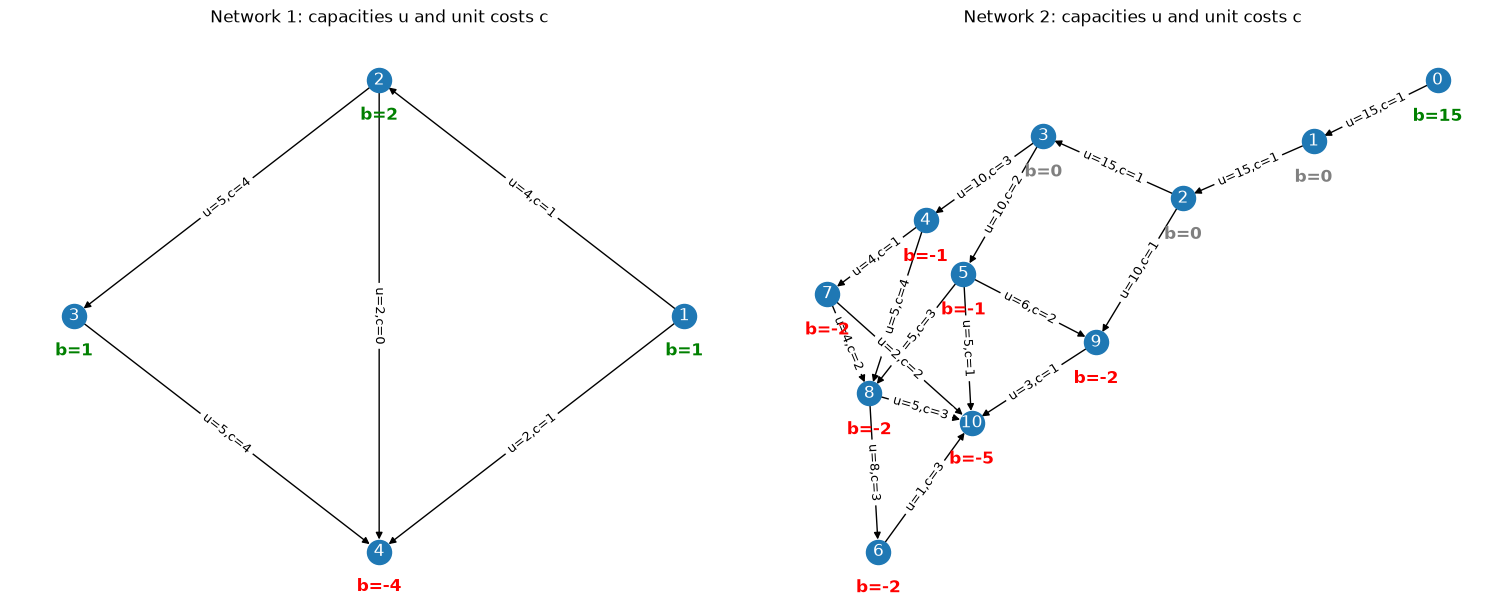

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
for ax, network, title in zip(axes, [network_1, network_2], ["Network 1", "Network 2"]):
    draw_network(network, ax=ax)
    ax.set_title(title + ": capacities u and unit costs c")
plt.show()

### Solution

In [11]:
def build_mcf(network):
    model = pyo.ConcreteModel(name="Minimum-cost flow")
    model.nodes = pyo.Set(initialize=list(network["nodes"]))
    model.arcs = pyo.Set(initialize=list(network["edges"]), dimen=2)
    model.flow = pyo.Var(model.arcs, domain=pyo.NonNegativeReals)
    model.objective = pyo.Objective(
        expr=sum(data["c"] * model.flow[edge] for edge, data in network["edges"].items())
    )

    @model.Constraint(model.nodes)
    def balance(m, v):
        outgoing = sum(m.flow[i, j] for i, j in m.arcs if i == v)
        incoming = sum(m.flow[i, j] for i, j in m.arcs if j == v)
        return outgoing - incoming == network["nodes"][v]["b"]

    @model.Constraint(model.arcs)
    def capacity_limit(m, i, j):
        return m.flow[i, j] <= network["edges"][i, j]["u"]

    return model

Network 1, termination: optimal; optimal cost: 5.000


,,Flow,Capacity,Unit cost
From,To,,,
1,2,0.000,4,1
2,3,0.000,5,4
3,4,1.000,5,4
1,4,1.000,2,1
2,4,2.000,2,0


Network 2, termination: optimal; optimal cost: 93.000


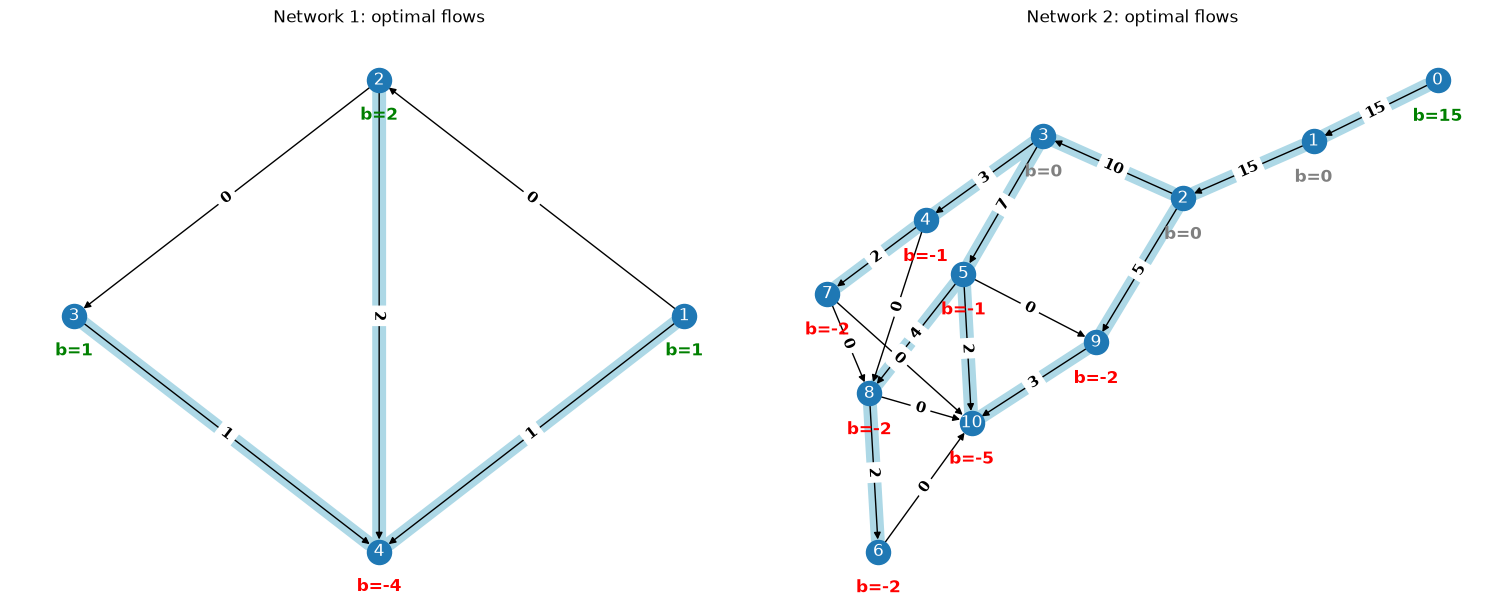

In [12]:
mcf_models = []
mcf_flows = []
for number, network in enumerate([network_1, network_2], start=1):
    model = build_mcf(network)
    result = solve_and_load(model)
    flows = {edge: pyo.value(model.flow[edge]) for edge in network["edges"]}
    mcf_models.append(model)
    mcf_flows.append(flows)
    flow_table = pd.DataFrame([
        {"From": i, "To": j, "Flow": flows[i, j], "Capacity": data["u"], "Unit cost": data["c"]}
        for (i, j), data in network["edges"].items()
    ]).set_index(["From", "To"])
    print(f"Network {number}, termination: {result.solver.termination_condition}; "
          f"optimal cost: {pyo.value(model.objective):.3f}")
    display(flow_table.style.format({"Flow": format_number}))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
for number, (ax, network, flows) in enumerate(zip(axes, [network_1, network_2], mcf_flows), start=1):
    # Round only the display copy; keep mcf_flows at full precision.
    plot_flows = {edge: round(value, 3) for edge, value in flows.items()}
    plot_flows = {edge: int(value) if value == int(value) else value for edge, value in plot_flows.items()}
    draw_network(network, ax=ax, edge_flows=plot_flows)
    ax.set_title(f"Network {number}: optimal flows")
plt.show()

## Exercise 5: graph coloring

Find a label **A**, **B** or **C** for every vertex of each graph below so that
adjacent vertices have different labels. Graph 1 is the octahedral graph
$K_{2,2,2}$; Graph 2 is the Petersen graph.

Formulate a binary integer model, implement `build_coloring(graph)`, and display
one feasible labeling of each graph. Every vertex must have **exactly one**
label. This is a feasibility problem: a constant objective of zero is sufficient.
You are not asked to minimize the number of colors.

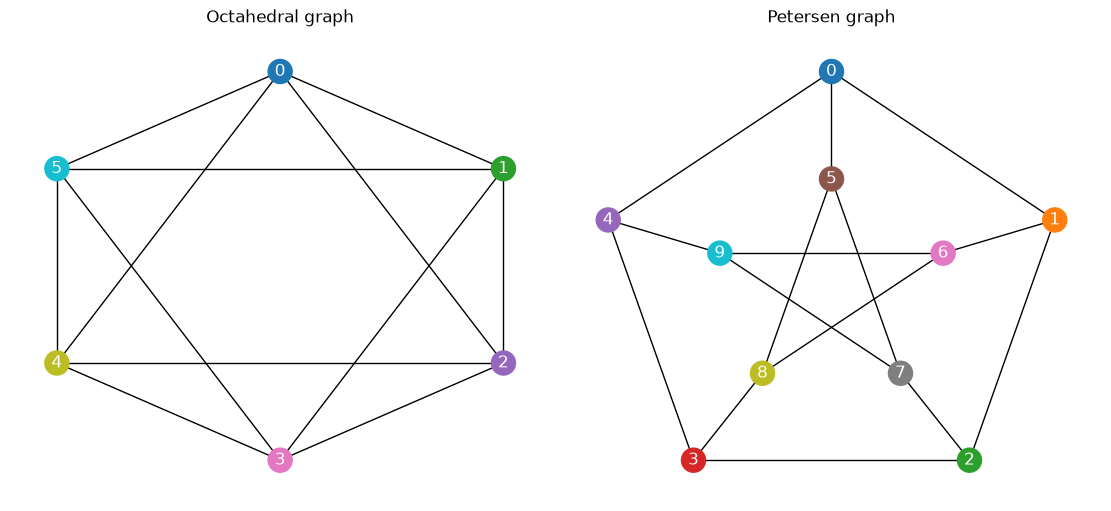

In [13]:
graph_1 = {
    "nodes": list(range(6)),
    "edges": [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0),
              (0, 2), (2, 4), (4, 0), (1, 3), (3, 5), (5, 1)],
}
graph_2 = {
    "nodes": list(range(10)),
    "edges": [(0, 1), (1, 2), (2, 3), (3, 4), (4, 0),
              (0, 5), (1, 6), (2, 7), (3, 8), (4, 9),
              (5, 7), (7, 9), (9, 6), (6, 8), (8, 5)],
}

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, graph, title in zip(axes, [graph_1, graph_2], ["Octahedral graph", "Petersen graph"]):
    draw_graph(graph, ax=ax)
    ax.set_title(title)
plt.show()

### Solution

For $k\in K=\{A,B,C\}$, let $z_{vk}=1$ if vertex $v$ has label $k$. Use

$$
\begin{aligned}
\min\quad &0\\
\text{s.t.}\quad &\sum_{k\in K}z_{vk}=1 &&\text{for each vertex }v,\\
&z_{ik}+z_{jk}\le1 &&\text{for each edge }(i,j)\text{ and label }k,\\
&z_{vk}\in\{0,1\}.
\end{aligned}
$$

The objective does not rank feasible colorings. Minimizing the total number of
vertex-label assignments would not count distinct colors: with exactly one label
per vertex, that sum is always $|V|$.

Graph 1, termination: optimal


,Label
Vertex,
0,C
1,B
2,A
3,C
4,B
5,A


Graph 2, termination: optimal


,Label
Vertex,
0,A
1,C
2,A
3,B
4,C
5,B
6,B
7,C
8,A


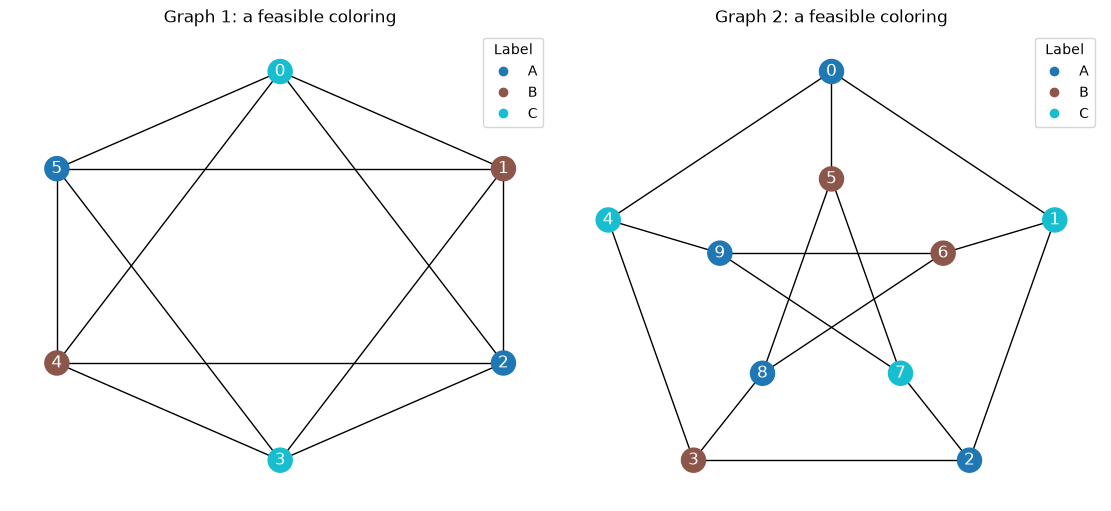

In [14]:
def build_coloring(graph, colors=("A", "B", "C")):
    model = pyo.ConcreteModel(name="Graph coloring")
    model.nodes = pyo.Set(initialize=graph["nodes"])
    model.edges = pyo.Set(initialize=graph["edges"], dimen=2)
    model.colors = pyo.Set(initialize=colors)
    model.label = pyo.Var(model.nodes, model.colors, domain=pyo.Binary)
    model.objective = pyo.Objective(expr=0)

    @model.Constraint(model.nodes)
    def one_label(m, v):
        return sum(m.label[v, k] for k in m.colors) == 1

    @model.Constraint(model.edges, model.colors)
    def adjacent_labels(m, i, j, k):
        return m.label[i, k] + m.label[j, k] <= 1

    return model

coloring_models = []
colorings = []
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for number, (ax, graph) in enumerate(zip(axes, [graph_1, graph_2]), start=1):
    model = build_coloring(graph)
    result = solve_and_load(model)
    labels = {v: next(k for k in model.colors if pyo.value(model.label[v, k]) > 0.5)
              for v in model.nodes}
    coloring_models.append(model)
    colorings.append(labels)
    print(f"Graph {number}, termination: {result.solver.termination_condition}")
    display(pd.Series(labels, name="Label").rename_axis("Vertex").to_frame())
    draw_graph(graph, ax=ax, node_labels=labels)
    handles, _ = ax.collections[0].legend_elements(num=None)
    ax.legend(handles, sorted(set(labels.values())), title="Label")
    ax.set_title(f"Graph {number}: a feasible coloring")
plt.show()

Colorings may differ, and any permutation of A, B and C is equally valid. Both
graphs contain an odd cycle (a triangle in Graph 1, the outer five-cycle in Graph 2), so
neither can be colored with two labels. A feasible three-label solution therefore
also shows that their chromatic number is three. In the plots, the vertex colors
encode the labels listed in the tables.

## Exercise 6: container shipping

A company has ships $i\in I$, with capacities $c_i$ containers, and must collect
$d_j$ containers from each port $j\in J$. Several ships may collect from the same
port. Ship $i$ incurs a fixed cost $f_{ij}$ whenever it visits port $j$, regardless
of the number collected there.

Treat each ship's capacity as a limit on its **total** pickup across all ports.
Routes, sailing order and unloading during the collection period are outside
this model. Containers are indivisible.

### 6(a): choosing visits and pickups

Formulate and solve an integer linear program that minimizes total visit cost
using the data below. Infer the ships and ports from the data labels.

1. Introduce visit binaries and pickup quantities. Derive a valid upper bound
   $M_{ij}$ for the linking constraint from the capacities and demands. What are
   its units? Also find the smallest uniform bound justified by these individual
   capacity and demand limits.
2. Solve with uniform $M=10,50,100,130,500,1000,10000$, and with your bounds
   $M_{ij}$. Identify which choices preserve the full intended feasible set.
   Handle infeasibility before trying to read a solution.
3. For each formulation, report its variable/constraint counts, plain LP value,
   processed root bound, LP/root gaps relative to the full MILP optimum,
   full-solve node count and observed time. Use a fresh model for every run and
   relax **all** integer variables for the LP. The supplied `compare_formulation`
   limits the root run with `options={"mip_max_nodes": 1}`.
   Distinguish a proven bound from an incumbent,
   which may be absent. Explain why a stronger LP bound need not mean a faster
   solve.
4. Display an optimal integer shipping plan and, separately, the fractional LP
   solution for $M=10000$. Keep fractional visit values visible.
5. Implement `add_visit_rows(model)` to add $\sum_i x_{ij}\ge1$ for every
   positive-demand port. Prove validity for
   the integer model. Before solving, predict which formulations these rows can
   strengthen. Compare $M=10000$ and pair-specific linking with and without them.
6. Identify the most violated visit row in the $M=10000$ LP and explain why its
   identity does not depend on which optimal LP solution is returned, using the
   positive visit costs. Prove that the pair-specific LP already implies every
   visit row.
7. Interpret the supplied root-log excerpt. Why can its first LP value differ
   from the plain LP, and why can a reported integer bound differ from the last
   fractional bound in the log?

Use HiGHS with its default presolve and cuts for all these comparisons. A single
timing is an observation about this run, not a reliable ranking of formulations.
On this small instance, presolve and cuts can largely hide the runtime effect of
the different bounds; the LP relaxation values show their strength more clearly.

In [15]:
capacity_values = [100, 150, 200, 250, 300]
demand_values = [48, 53, 77, 74, 98, 103, 108, 114, 122, 130]
capacity = pd.Series(capacity_values,
                     index=[f"Ship {i + 1}" for i in range(len(capacity_values))],
                     name="Capacity (containers)")
demand = pd.Series(demand_values,
                   index=[f"Port {j + 1}" for j in range(len(demand_values))],
                   name="Demand (containers)")
cost = pd.DataFrame(
    [[115, 368, 112, 466, 206],
     [397, 240, 303, 411, 371],
     [195, 228, 433, 258, 432],
     [478, 185, 306, 422, 475],
     [342, 417, 438, 281, 355],
     [202, 342, 228, 375, 379],
     [180, 113, 331, 355, 116],
     [239, 208, 381, 484, 323],
     [344, 301, 249, 224, 419],
     [258, 419, 347, 293, 254]],
    columns=capacity.index, index=demand.index,
)
display_side_by_side(
    [cost, capacity.to_frame(), demand.to_frame()],
    ["Visit costs f (ports × ships)", "Ship capacities c", "Port demands d"],
)
print(f"Total demand: {demand.sum()} containers; total capacity: {capacity.sum()} containers")

,Ship 1,Ship 2,Ship 3,Ship 4,Ship 5
Port 1,115,368,112,466,206
Port 2,397,240,303,411,371
Port 3,195,228,433,258,432
Port 4,478,185,306,422,475
Port 5,342,417,438,281,355
Port 6,202,342,228,375,379
Port 7,180,113,331,355,116
Port 8,239,208,381,484,323
Port 9,344,301,249,224,419
Port 10,258,419,347,293,254


Total demand: 927 containers; total capacity: 1000 containers


The cost table has ports as rows and ships as columns: the mathematical
$f_{ij}$ (ship $i$, port $j$) is accessed as `cost.loc[j, i]` in Python.

### Solution to 6(a)

Let $x_{ij}\in\{0,1\}$ indicate whether ship $i$ visits port $j$, and let
$y_{ij}\in\mathbb{Z}_{\ge0}$ count the containers it collects there. The model is

$$
\begin{aligned}
\min\quad &\sum_{i\in I,j\in J}f_{ij}x_{ij}\\
\text{s.t.}\quad &y_{ij}\le M_{ij}x_{ij} &&\text{for each }i,j,\\
&\sum_{j\in J}y_{ij}\le c_i &&\text{for each ship }i,\\
&\sum_{i\in I}y_{ij}=d_j &&\text{for each port }j,\\
&x_{ij}\in\{0,1\},\quad y_{ij}\in\mathbb{Z}_{\ge0}.
\end{aligned}
$$

No pickup can exceed either a ship's capacity or the port's demand. Thus
$M_{ij}=\min(c_i,d_j)$ is valid and is measured in **containers**, not money.
The smallest uniform bound implied by these separate limits is
$\max_{i,j}\min(c_i,d_j)=130$ for these data. Smaller uniform values impose extra
restrictions and may exclude optimal plans or make the problem infeasible.

The LP relaxation replaces $x_{ij}\in\{0,1\}$ by $0\le x_{ij}\le1$ and
$y_{ij}\in\mathbb{Z}_{\ge0}$ by $y_{ij}\ge0$. Its cost is a lower bound for the
corresponding integer model. For a restricted choice of $M$, that LP value need
not be a lower bound for the original shipping problem.

In [16]:
def build_shipping(capacity, demand, cost, upper):
    '''Build the MILP; upper[i, j] is the proposed pickup bound in containers.'''
    model = pyo.ConcreteModel(name="Container shipping")
    model.ships = pyo.Set(initialize=capacity.index)
    model.ports = pyo.Set(initialize=demand.index)
    model.visit = pyo.Var(model.ships, model.ports, domain=pyo.Binary)
    model.pickup = pyo.Var(model.ships, model.ports, domain=pyo.NonNegativeIntegers)
    model.objective = pyo.Objective(
        expr=sum(cost.loc[j, i] * model.visit[i, j] for i in model.ships for j in model.ports)
    )

    @model.Constraint(model.ships, model.ports)
    def link(m, i, j):
        return m.pickup[i, j] <= upper[i, j] * m.visit[i, j]

    @model.Constraint(model.ships)
    def ship_capacity(m, i):
        return sum(m.pickup[i, j] for j in m.ports) <= capacity[i]

    @model.Constraint(model.ports)
    def port_demand(m, j):
        return sum(m.pickup[i, j] for i in m.ships) == demand[j]

    return model

`solve` returns `status`, `objective`, `bound`, `gap`, `nodes` and `time`.
An `optimal` status certifies the optimum. A limited run can load an incumbent
without proving it optimal; its status can be `other`, and `objective` can be
`None`. Inspect the status before reading model values. For minimization, the
root bound is a lower bound; it need not equal the plain LP value.

Use the reporting scaffold below for shipping and part 6(c). Its LP/root gaps
are percentages relative to the **proven full MILP optimum**, when available.
The helper's own `gap` is instead a fraction relative to that run's incumbent.

In [17]:
def compare_formulation(build):
    models, reports = {}, {}
    for kind in ("LP", "Root", "MILP"):
        model = build()
        if kind == "LP":
            relax_integrality(model)
        options = {"mip_max_nodes": 1} if kind == "Root" else None
        reports[kind] = solve(model, options=options)
        models[kind] = model
    full = reports["MILP"]
    optimum = full["objective"] if full["status"] == "optimal" else None
    def gap_percent(bound):
        if optimum is None or bound is None:
            return None
        return 100 * (optimum - bound) / max(abs(optimum), 1e-12)
    row = {
        "Variables": sum(1 for _ in models["MILP"].component_data_objects(pyo.Var)),
        "Rows": sum(1 for _ in models["MILP"].component_data_objects(pyo.Constraint, active=True)),
        "LP status": reports["LP"]["status"], "LP value": reports["LP"]["objective"],
        "LP gap (%)": gap_percent(reports["LP"]["objective"]),
        "Root status": reports["Root"]["status"], "Root bound": reports["Root"]["bound"],
        "Root incumbent": reports["Root"]["objective"],
        "Root gap (%)": gap_percent(reports["Root"]["bound"]),
        "MILP status": full["status"], "MILP value": full["objective"],
        "MILP nodes": full["nodes"], "MILP seconds": full["time"],
    }
    return row, models, reports

In [18]:
tight_upper = {(i, j): min(capacity[i], demand[j])
               for i in capacity.index for j in demand.index}
uniform_bound = max(tight_upper.values())
bound_choices = {
    f"M = {M}": {(i, j): M for i in capacity.index for j in demand.index}
    for M in [10, 50, 100, 130, 500, 1000, 10000]
}
bound_choices["M_ij = min(c_i, d_j)"] = tight_upper

shipping_models, shipping_reports = {}, {}
comparison_rows = []
for name, upper in bound_choices.items():
    row, models, reports = compare_formulation(
        lambda upper=upper: build_shipping(capacity, demand, cost, upper)
    )
    row.update(Choice=name,
               **{"Valid for full model": all(upper[p] >= b for p, b in tight_upper.items())})
    for kind in ("LP", "MILP"):
        shipping_models[name, kind] = models[kind]
    shipping_reports[name] = reports
    comparison_rows.append(row)

shipping_comparison = pd.DataFrame(comparison_rows).set_index("Choice")
display(shipping_comparison[["Variables", "Rows", "Valid for full model", "LP status", "LP value",
                             "LP gap (%)", "Root bound", "Root gap (%)"]]
        .style.format(precision=2, na_rep="unavailable"))
display(shipping_comparison[["Root status", "Root incumbent", "MILP status", "MILP value",
                             "MILP nodes", "MILP seconds"]]
        .style.format(precision=2, na_rep="unavailable"))

,Variables,Rows,Valid for full model,LP status,LP value,LP gap (%),Root bound,Root gap (%)
Choice,,,,,,,,
M = 10,100,65,False,infeasible,unavailable,unavailable,unavailable,unavailable
M = 50,100,65,False,optimal,4539.40,22.62,5823.00,0.73
M = 100,100,65,False,optimal,2037.12,36.79,3223.00,0.00
M = 130,100,65,True,optimal,1538.44,37.18,2204.00,10.00
M = 500,100,65,True,optimal,399.99,83.67,2204.00,10.00
M = 1000,100,65,True,optimal,200.00,91.83,2204.00,10.00
M = 10000,100,65,True,optimal,20.00,99.18,2204.00,10.00
"M_ij = min(c_i, d_j)",100,65,True,optimal,2125.68,13.20,2204.00,10.00


,Root status,Root incumbent,MILP status,MILP value,MILP nodes,MILP seconds
Choice,,,,,,
M = 10,infeasible,unavailable,infeasible,unavailable,0,0.00
M = 50,other,5866.00,optimal,5866.00,1,0.16
M = 100,optimal,3223.00,optimal,3223.00,1,0.12
M = 130,other,2449.00,optimal,2449.00,432,0.51
M = 500,other,2449.00,optimal,2449.00,432,0.51
M = 1000,other,2449.00,optimal,2449.00,432,0.51
M = 10000,other,2449.00,optimal,2449.00,432,0.51
"M_ij = min(c_i, d_j)",other,2449.00,optimal,2449.00,432,0.52


The $M=50$ and $M=100$ optima belong to **restricted** problems. The $M=10$ case
is infeasible. Use only the valid choices when comparing formulations.
Decreasing a valid bound tightens the LP feasible set, so its lower bound cannot
decrease. Presolve, cuts, heuristics and timing noise can nevertheless change the
runtime ordering; the table does not establish a universal timing rule.

The next cell displays the MILP plan with the pair-specific bounds. Binary visits
are identified using `> 0.5`; pickup quantities are retained at full precision and
formatted as whole containers only for display.

In [19]:
shipping_model = shipping_models["M_ij = min(c_i, d_j)", "MILP"]
pickup_plan = pd.DataFrame(
    {i: {j: pyo.value(shipping_model.pickup[i, j]) for j in demand.index} for i in capacity.index}
)
visit_plan = pd.DataFrame(
    {i: {j: int(pyo.value(shipping_model.visit[i, j]) > 0.5) for j in demand.index} for i in capacity.index}
)
display(pickup_plan.style.format(lambda value: format_number(value, 0))
        .set_caption("Optimal MILP: containers picked up"))
display(visit_plan.style.set_caption("Optimal MILP: visits (0 or 1)"))
print(f"Optimal visit cost: {pyo.value(shipping_model.objective):.2f}")

,Ship 1,Ship 2,Ship 3,Ship 4,Ship 5
Port 1,23,0,25,0,0
Port 2,0,0,53,0,0
Port 3,77,0,0,0,0
Port 4,0,74,0,0,0
Port 5,0,0,0,98,0
Port 6,0,0,103,0,0
Port 7,0,52,0,0,56
Port 8,0,0,0,0,114
Port 9,0,0,0,122,0
Port 10,0,0,0,0,130


,Ship 1,Ship 2,Ship 3,Ship 4,Ship 5
Port 1,1,0,1,0,0
Port 2,0,0,1,0,0
Port 3,1,0,0,0,0
Port 4,0,1,0,0,0
Port 5,0,0,0,1,0
Port 6,0,0,1,0,0
Port 7,0,1,0,0,1
Port 8,0,0,0,0,1
Port 9,0,0,0,1,0
Port 10,0,0,0,0,1


Optimal visit cost: 2449.00


For $M=10000$, the LP allows substantial pickups while charging only a small
fraction of the fixed visit cost. The LP table below gives a **bound**, not an
implementable plan. Do not threshold or round its visit variables to integers:
zero displayed visits alongside positive pickups would conceal the linking
constraint. A value such as 0.013 is a fractional decision, not a numerical zero.

In [20]:
shipping_lp = shipping_models["M = 10000", "LP"]
fractional_visits = pd.DataFrame(
    {i: {j: pyo.value(shipping_lp.visit[i, j]) for j in demand.index} for i in capacity.index}
)
fractional_pickups = pd.DataFrame(
    {i: {j: pyo.value(shipping_lp.pickup[i, j]) for j in demand.index} for i in capacity.index}
)
print(f"LP lower bound with M = 10000: {pyo.value(shipping_lp.objective):.4f}")
display(fractional_visits.style.format(lambda value: format_number(value, 5))
        .set_caption("LP relaxation: fractional visits"))
display(fractional_pickups.style.format(format_number).set_caption("LP relaxation: container quantities"))

LP lower bound with M = 10000: 19.9997


,Ship 1,Ship 2,Ship 3,Ship 4,Ship 5
Port 1,0.00000,0.00000,0.00480,0.00000,0.00000
Port 2,0.00000,0.00040,0.00490,0.00000,0.00000
Port 3,0.00580,0.00000,0.00000,0.00190,0.00000
Port 4,0.00000,0.00740,0.00000,0.00000,0.00000
Port 5,0.00000,0.00000,0.00000,0.00980,0.00000
Port 6,0.00000,0.00000,0.01030,0.00000,0.00000
Port 7,0.00000,0.00000,0.00000,0.00000,0.01080
Port 8,0.00420,0.00720,0.00000,0.00000,0.00000
Port 9,0.00000,0.00000,0.00000,0.01220,0.00000
Port 10,0.00000,0.00000,0.00000,0.00000,0.01300


,Ship 1,Ship 2,Ship 3,Ship 4,Ship 5
Port 1,0.000,0.000,48.000,0.000,0.000
Port 2,0.000,4.000,49.000,0.000,0.000
Port 3,58.000,0.000,0.000,19.000,0.000
Port 4,0.000,74.000,0.000,0.000,0.000
Port 5,0.000,0.000,0.000,98.000,0.000
Port 6,0.000,0.000,103.000,0.000,0.000
Port 7,0.000,0.000,0.000,0.000,108.000
Port 8,42.000,72.000,0.000,0.000,0.000
Port 9,0.000,0.000,0.000,122.000,0.000
Port 10,0.000,0.000,0.000,0.000,130.000


### Visit inequalities and root processing

Use the cells below for parts 5–7 of 6(a).

In [21]:
def add_visit_rows(model):
    model.visit_required = pyo.Constraint(
        [j for j in model.ports if demand[j] > 0],
        rule=lambda m, j: sum(m.visit[i, j] for i in m.ships) >= 1,
    )
    return model

visit_rows, visit_models, visit_reports = [], {}, {}
for name, upper in (("M = 10000", bound_choices["M = 10000"]),
                    ("M_ij = min(c_i, d_j)", tight_upper)):
    row, models, reports = compare_formulation(
        lambda upper=upper: add_visit_rows(build_shipping(capacity, demand, cost, upper))
    )
    row["Choice"] = name + " + visit rows"
    visit_rows.append(row)
    visit_models[name] = models
    visit_reports[name] = reports
visit_comparison = pd.DataFrame(visit_rows).set_index("Choice")
display(visit_comparison[["Variables", "Rows", "LP value", "LP gap (%)", "Root bound",
                          "Root gap (%)", "MILP value", "MILP nodes", "MILP seconds"]]
        .style.format(precision=2, na_rep="unavailable"))
visit_sums = fractional_visits.sum(axis=1)
visit_violations = (1 - visit_sums).clip(lower=0)
print(f"Most violated port: {visit_violations.idxmax()}; "
      f"violation {visit_violations.max():.4f}")

,Variables,Rows,LP value,LP gap (%),Root bound,Root gap (%),MILP value,MILP nodes,MILP seconds
Choice,,,,,,,,,
M = 10000 + visit rows,100,75,2014.86,17.73,2211.00,9.72,2449.00,107,0.48
"M_ij = min(c_i, d_j) + visit rows",100,75,2125.68,13.20,2211.00,9.72,2449.00,107,0.48


Most violated port: Port 1; violation 0.9952


A positive demand requires a positive pickup from at least one ship, whose binary
visit must then equal one. The visit row is therefore valid. For the pair-specific
LP, nonnegativity gives

$$
d_j=\sum_i y_{ij}\le\sum_i\min(c_i,d_j)x_{ij}
    \le d_j\sum_i x_{ij}.
$$

Since $d_j>0$, the visit row follows. It leaves this LP feasible set unchanged.
For the uniform $M=10000$ LP, positive visit costs force $x_{ij}=y_{ij}/10000$
at every optimum. Hence $\sum_i x_{ij}=d_j/10000$; Port 1, whose demand is 48,
has the largest violation, $1-48/10000=0.9952$, for every optimal LP solution.

The added rows raise the weak LP bound to 2014.86; the pair-specific bound stays
2125.68. Both MILPs still have value 2449. Even a row redundant for the LP can
change processing and the search tree. The measured root bounds and node counts
are observations of this solver run, not formulation invariants.

The following abbreviated **reference root log** is from the root-limited run
with `options={"mip_max_nodes": 1}`, HiGHS 1.15.1, $M=10000$ and default
presolve/cuts. Read it alongside your measured table. A full solve can follow a
different processing path and give a different last root bound.

| Logged event | Interpretation |
|:---|:---|
| Presolve: `Not reduced` | No row/column reduction is reported; this does not rule out coefficient strengthening. |
| First root LP: 2125.68; zero cuts | Processing has already strengthened the plain relaxation. |
| Subsequent cut rows raise the bound | These are processed bounds, not new plain-LP values. |
| `L` finds incumbent 2449 | A sub-MIP heuristic found a feasible integer solution. |
| Restart after 4% inactive integer columns | HiGHS changes the remaining search representation. |
| Last fractional bound about 2203.30; reported bound 2204 | The objective is integer-valued, so its lower bound can be rounded upward. |

The plain $M=10000$ LP has value about 20 (19.9997). Equal processed bounds across
formulations do not identify which internal strengthening operation was responsible.
A root-limited status of `other` is compatible with a valid incumbent and bound;
it does not prove optimality. Optional: turn presolve off for one diagnostic
comparison rather than repeating the entire sweep.

### 6(b): minimizing the fleet size

For a long-term decision, the company may obtain any number of ships of any of the
five capacity types in part (a). It wants to minimize the **number of ships**;
purchase prices and port visit costs are ignored. Now each port's entire demand
must be collected by **exactly one ship**. A ship may serve several ports, subject
to its capacity.

Explain why the model can restrict attention to the largest capacity type. Then
formulate and solve an integer model with individual candidate ships and port
assignment variables. Give a lower bound on the number of ships and display a
feasible allocation attaining the optimum.

### Solution to 6(b)

Every ship counts equally and copies are unlimited. Replacing a smaller ship by
a 300-container ship cannot increase the fleet size or invalidate an assignment.
Thus an optimal fleet using only the largest type exists. Under these assumptions,
there is no meaningful trade-off between ship types.

Use $|J|$ candidate ships, indexed by $k\in K$. This suffices because every port's
demand fits in one largest ship, so one ship per port is a feasible upper bound.
Let $u_k$ indicate whether ship $k$ is used, and $a_{kj}$ whether port $j$ is
assigned to it. With largest capacity $C$, solve

$$
\begin{aligned}
\min\quad &\sum_{k\in K}u_k\\
\text{s.t.}\quad &\sum_{k\in K}a_{kj}=1 &&\text{for each port }j,\\
&\sum_{j\in J}d_j a_{kj}\le Cu_k &&\text{for each ship }k,\\
&a_{kj},u_k\in\{0,1\}.
\end{aligned}
$$

All demands here are positive, so the capacity row also prevents assigning a port
to an unused ship. A lower bound is $\lceil\sum_j d_j/C\rceil$; indivisible port
assignments can make the true optimum larger for other data.

In [22]:
from math import ceil

def build_fleet(demand, largest_capacity):
    if (demand <= 0).any() or (demand > largest_capacity).any():
        raise ValueError("Each port demand must be positive and fit in one largest ship.")
    model = pyo.ConcreteModel(name="Minimum fleet with one ship per port")
    model.ships = pyo.RangeSet(1, len(demand))
    model.ports = pyo.Set(initialize=demand.index)
    model.used = pyo.Var(model.ships, domain=pyo.Binary)
    model.assign = pyo.Var(model.ships, model.ports, domain=pyo.Binary)
    model.objective = pyo.Objective(expr=sum(model.used[k] for k in model.ships))

    @model.Constraint(model.ports)
    def one_ship(m, j):
        return sum(m.assign[k, j] for k in m.ships) == 1

    @model.Constraint(model.ships)
    def ship_capacity(m, k):
        return sum(demand[j] * m.assign[k, j] for j in m.ports) <= largest_capacity * m.used[k]

    return model

largest_capacity = capacity.max()
fleet_model = build_fleet(demand, largest_capacity)
result = solve_and_load(fleet_model)
fleet_plan = []
for k in fleet_model.ships:
    if pyo.value(fleet_model.used[k]) > 0.5:
        ports = [j for j in fleet_model.ports if pyo.value(fleet_model.assign[k, j]) > 0.5]
        fleet_plan.append({"Ship": k, "Ports": ", ".join(ports),
                           "Load (containers)": demand[ports].sum(), "Capacity": largest_capacity})

print(f"Termination: {result.solver.termination_condition}")
print(f"Capacity lower bound: {ceil(demand.sum() / largest_capacity)} ships")
print(f"Optimal fleet size: {pyo.value(fleet_model.objective):.0f} ships")
fleet_table = pd.DataFrame(fleet_plan).set_index("Ship")
# Candidate ships are interchangeable; number the displayed fleet consecutively.
fleet_table.index = pd.RangeIndex(1, len(fleet_table) + 1, name="Ship")
display(fleet_table)

Termination: optimal
Capacity lower bound: 4 ships
Optimal fleet size: 4 ships


,Ports,Load (containers),Capacity
Ship,,,
1,"Port 1, Port 2, Port 4, Port 6",278,300
2,"Port 3, Port 5, Port 8",289,300
3,Port 7,108,300
4,"Port 9, Port 10",252,300


### 6(c): aggregated versus individual linking

An uncapacitated facility-location model opens facilities $j\in J$ at costs
$F_j$ and allocates each customer $k\in K$ among open facilities. Let
$o_j\in\{0,1\}$ indicate an opening and let $s_{jk}\in[0,1]$ be the allocation
fraction. Minimize

$$
\sum_j F_jo_j+\sum_{j,k}C_{jk}s_{jk},\qquad \sum_j s_{jk}=1\quad(k\in K).
$$

Compare aggregated linking $\sum_k s_{jk}\le |K|o_j$ with individual linking
$s_{jk}\le o_j$ for every $j,k$.

1. Complete `build_location(data, strong=False)` using the supplied scaffold.
   Explain why the two formulations are equivalent for binary openings, why the
   individual-linking LP is contained in the aggregated-linking LP, and why the
   reverse inclusion fails. Give a fractional counterexample.
2. Predict and compare LP and MILP values for the two-facility example. Then use
   the fixed larger instance, preserving the order of its random-generator calls.
   Reuse the reporting scaffold from 6(a), including processed root bounds,
   model sizes and full-solve effort. Do not infer a runtime ranking from one run.
3. Explain why continuous allocation fractions lose nothing for fixed openings.
   Does an integral optimum of the strong LP on these data prove that its
   polytope is integral in general?

Lecture 2, slide 22, asks why individual linking gives a stronger formulation.
It uses $y_j,x_{ij},c_j,h_{ij}$ for our $o_j,s_{ji},F_j,C_{ji}$,
respectively; the customer index $i$ there is $k$ here.

In [23]:
toy_location = {
    "open_cost": np.array([10, 10]),
    "ship_cost": np.array([[0, 100], [100, 0]]),
}

rng = np.random.default_rng(2026)
facility_xy = rng.uniform(0, 100, (10, 2))
customer_xy = rng.uniform(0, 100, (40, 2))
open_cost = rng.integers(150, 300, 10)
distance = np.linalg.norm(facility_xy[:, None, :] - customer_xy[None, :, :], axis=2)
ship_cost = np.rint(distance)
large_location = {"open_cost": open_cost, "ship_cost": ship_cost}
print(f"Larger instance: {len(open_cost)} facilities, {ship_cost.shape[1]} customers")


def location_scaffold(data):
    F, C = data["open_cost"], data["ship_cost"]
    model = pyo.ConcreteModel(name="Uncapacitated facility location")
    model.facilities = pyo.RangeSet(0, len(F) - 1)
    model.customers = pyo.RangeSet(0, C.shape[1] - 1)
    model.open = pyo.Var(model.facilities, domain=pyo.Binary)
    model.allocation = pyo.Var(model.facilities, model.customers, bounds=(0, 1))
    model.objective = pyo.Objective(
        expr=sum(F[j] * model.open[j] for j in model.facilities)
        + sum(C[j, k] * model.allocation[j, k]
              for j in model.facilities for k in model.customers)
    )
    model.serve = pyo.Constraint(
        model.customers,
        rule=lambda m, k: sum(m.allocation[j, k] for j in m.facilities) == 1,
    )
    return model

Larger instance: 10 facilities, 40 customers


In [24]:
def build_location(data, strong=False):
    model = location_scaffold(data)
    if strong:
        model.link = pyo.Constraint(
            model.facilities, model.customers,
            rule=lambda m, j, k: m.allocation[j, k] <= m.open[j],
        )
    else:
        model.link = pyo.Constraint(
            model.facilities,
            rule=lambda m, j: sum(m.allocation[j, k] for k in m.customers)
            <= len(m.customers) * m.open[j],
        )
    return model

location_models, location_reports, location_rows = {}, {}, []
for instance, data in (("Two customers", toy_location), ("Forty customers", large_location)):
    for strong in (False, True):
        name = (instance, "Individual" if strong else "Aggregated")
        row, models, reports = compare_formulation(
            lambda data=data, strong=strong: build_location(data, strong)
        )
        row.update(Instance=name[0], Linking=name[1])
        location_rows.append(row)
        location_models[name] = models
        location_reports[name] = reports
location_comparison = pd.DataFrame(location_rows).set_index(["Instance", "Linking"])
display(location_comparison[["Variables", "Rows", "LP value", "LP gap (%)",
                             "Root bound", "Root gap (%)"]].style.format(precision=2))
display(location_comparison[["Root status", "Root incumbent", "MILP status", "MILP value",
                             "MILP nodes", "MILP seconds"]].style.format(precision=2))

For a closed facility, either formulation forces every allocation to zero. For
an open facility, $s_{jk}\le1$ already holds, so both linking choices impose no
additional restriction. They are therefore equivalent for binary openings.
Summing the individual LP rows gives the aggregated row. Conversely, in the
small example $o=(1/2,1/2)$ and $s_{11}=s_{22}=1$, $s_{12}=s_{21}=0$ satisfy the
assignment and aggregated rows but violate individual linking.

The small aggregated LP has value 10: at least one unit of opening is needed,
and the displayed fractional point attains that cost without shipping cost.
Individual linking requires $o_j\ge s_{jk}$, so each customer's zero-cost
allocation requires its facility to be open. More generally, the objective is
at least $20+90(s_{12}+s_{21})\ge20$, by $o_1\ge1-s_{21}$ and
$o_2\ge1-s_{12}$. Opening both facilities attains 20 for the individual LP
and either MILP; serving both from one facility would cost 110.

For the larger data, the aggregated LP has value 800.35, whereas the individual
LP and both MILPs have value 1447. There are 410 variables and respectively 50
and 440 rows. The root table shows how much of the plain-LP difference survives
processing. Node counts and times are properties of this run.

For fixed openings, each customer minimizes a linear cost over a simplex of
open facilities, so allocating it entirely to a cheapest open facility is
optimal. Fractions allow ties but do not improve the value. This observation
does not imply that the joint LP in opening and allocation variables is an
integral polytope. One integral LP optimum on this instance is insufficient.

What do the LP bounds, the visit-row validity and implication arguments, and the
solver termination statuses establish? Distinguish a feasible plan, a proven
optimum and an observed change in solver effort. Which conclusions rely on a
mathematical argument rather than a numerical run?